<a href="https://colab.research.google.com/github/mihirgohil1402-ui/Cfd-lab/blob/main/02_Double_Pipe_Heat_Exchanger.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 2: Double Pipe Heat Exchanger

**Name:** Mihir Gohil  |  **Roll No:** 23BME019  
**Course:** Computational Fluid Dynamics and Heat Transfer Lab (20ME406P), Department of Mechanical Engineering, PDEU


## 1. Aim
To model conjugate heat transfer in a planar double-pipe heat exchanger (cold stream, solid wall, hot stream), to obtain the steady temperature field, the bulk temperatures, the heat-transfer rate and the effectiveness for parallel and counter flow, and to study the effect of the Reynolds number, the Prandtl number and the wall-to-fluid conductivity ratio.

## 2. Problem and parameters
The exchanger is represented as three flat layers: a cold channel at the bottom, a solid wall in the middle and a hot channel at the top. The hot stream always flows in the +x direction. The cold stream flows in +x (parallel flow) or in −x (counter flow). The outer top and bottom edges are insulated and the wall ends are adiabatic. The velocity is **prescribed** (fully developed parabolic profile in each channel, zero in the wall); only the energy equation is solved.

| Parameter | Symbol | Value |
|---|---|---|
| Length of exchanger | L_x | 8 |
| Cold channel / wall / hot channel thickness | | 0.8 / 0.4 / 0.8 |
| Cells (base grid) | n_x × n_y | 160 × 40 (Δx = Δy = 0.05; 16, 8 and 16 rows) |
| Mean velocity in each channel | U | 1 |
| Reynolds number (base) | Re | 10 (also 5, 20, 50, 100) |
| Prandtl number (base) | Pr | 1 (also 0.7, 7) |
| Wall-to-fluid conductivity ratio (base) | k_s/k_f | 2 (also 0.2, 1, 5, 50) |
| Inlet temperatures | | hot = 1, cold = 0 |

Fluid conductivity in non-dimensional form: D_f = 1/(Re Pr). The solid conductivity is D_s = (k_s/k_f) D_f, with equal ρc_p in all layers.

## 3. Governing equation and method
$$\frac{\partial (uT)}{\partial x} = \frac{\partial}{\partial x}\left(D\frac{\partial T}{\partial x}\right)+\frac{\partial}{\partial y}\left(D\frac{\partial T}{\partial y}\right), \qquad D = D(y)$$

Cell-centred finite volume, steady state, solved directly as one sparse linear system. Convection uses the **upwind** value, diffusion the central difference, and the diffusivity on faces between different materials uses the **harmonic mean** so that the heat flux is continuous across the fluid–solid interface (the "conjugate" condition). Inlet faces are Dirichlet (half-cell distance), outlet faces are zero-gradient.

**Outputs.** Bulk temperature T_b(x) = Σ uT / Σ u of each stream. Heat-transfer rate Q = ṁc_p (T_b,out − T_b,in). Effectiveness ε = Q / Q_max, and since both streams have equal capacity rate, ε = (T_c,out − 0)/(1 − 0). For parallel flow ε can never exceed 0.5, which is a useful check.

In [1]:
import numpy as np
import scipy.sparse as sp
import scipy.sparse.linalg as spla
import matplotlib.pyplot as plt
import pandas as pd

Lx = 8.0
H_C, H_W, H_H = 0.8, 0.4, 0.8
T_HOT, T_COLD = 1.0, 0.0

def exchanger(Re=10, Pr=1.0, ksf=2.0, flow='counter', scale=1):
    dy = 0.05/scale
    nyc, nyw, nyh = int(round(H_C/dy)), int(round(H_W/dy)), int(round(H_H/dy))
    ny = nyc + nyw + nyh
    nx = int(round(Lx/dy))
    dx = Lx/nx
    Df = 1.0/(Re*Pr)
    # layer properties per row
    D = np.empty(ny); u = np.zeros(ny)
    kind = np.empty(ny, dtype='<U1')
    kind[:nyc] = 'c'; kind[nyc:nyc+nyw] = 'w'; kind[nyc+nyw:] = 'h'
    D[:nyc] = Df; D[nyc:nyc+nyw] = ksf*Df; D[nyc+nyw:] = Df
    # parabolic profiles with mean exactly 1 on the discrete grid
    for lo, n, sgn in ((0, nyc, -1.0 if flow == 'counter' else 1.0), (nyc+nyw, nyh, 1.0)):
        s = (np.arange(n)+0.5)/n
        prof = 6*s*(1-s)
        prof /= prof.mean()
        u[lo:lo+n] = sgn*prof
    Fe = u*dy                                # volumetric flux through a vertical face of each row
    Dface = 2*D[:-1]*D[1:]/(D[:-1] + D[1:])  # harmonic mean between rows j and j+1
    idx = lambda i, j: i*ny + j
    rows, cols, vals = [], [], []
    b = np.zeros(nx*ny)
    for i in range(nx):
        for j in range(ny):
            k = idx(i, j)
            aP = 0.0
            fe = Fe[j]; d = D[j]*dy/dx
            Tin = T_HOT if kind[j] == 'h' else T_COLD
            # east face
            if i < nx-1:
                aE = d + max(-fe, 0.0); aP += d + max(fe, 0.0)
                rows.append(k); cols.append(idx(i+1, j)); vals.append(-aE)
            elif kind[j] != 'w':
                if fe > 0:  aP += fe                                   # outflow, zero gradient
                else:       aP += 2*d; b[k] += (2*d + abs(fe))*Tin     # inflow (counter-flow cold stream), Dirichlet
            # west face
            if i > 0:
                aW = d + max(fe, 0.0); aP += d + max(-fe, 0.0)
                rows.append(k); cols.append(idx(i-1, j)); vals.append(-aW)
            elif kind[j] != 'w':
                if fe > 0:  aP += 2*d; b[k] += (2*d + abs(fe))*Tin     # inflow, Dirichlet
                else:       aP += abs(fe)                              # outflow
            # north face (y+): diffusion only, insulated at the top
            if j < ny-1:
                dn = Dface[j]*dx/dy
                aP += dn; rows.append(k); cols.append(idx(i, j+1)); vals.append(-dn)
            # south face (y-): diffusion only, insulated at the bottom
            if j > 0:
                ds = Dface[j-1]*dx/dy
                aP += ds; rows.append(k); cols.append(idx(i, j-1)); vals.append(-ds)
            rows.append(k); cols.append(k); vals.append(aP)
    A = sp.csc_matrix((vals, (rows, cols)), shape=(nx*ny, nx*ny))
    T = spla.splu(A).solve(b).reshape(nx, ny)
    xc = (np.arange(nx)+0.5)*dx
    yc = (np.arange(ny)+0.5)*dy
    # bulk temperatures along x
    ch = slice(0, nyc); hh = slice(nyc+nyw, ny)
    Tb_c = (T[:, ch]*np.abs(Fe[ch])).sum(1)/np.abs(Fe[ch]).sum()
    Tb_h = (T[:, hh]*np.abs(Fe[hh])).sum(1)/np.abs(Fe[hh]).sum()
    c_out = -1 if flow == 'parallel' else 0
    eff_cold = Tb_c[c_out] - T_COLD                        # heat gained by cold stream / Q_max
    eff_hot = T_HOT - Tb_h[-1]                             # heat lost by hot stream / Q_max
    return dict(T=T, xc=xc, yc=yc, Tb_c=Tb_c, Tb_h=Tb_h, eff_cold=eff_cold, eff_hot=eff_hot,
                Tc_out=Tb_c[c_out], Th_out=Tb_h[-1], flow=flow, nyc=nyc, nyw=nyw, nyh=nyh)

## 4. Base case: parallel and counter flow (Re = 10, Pr = 1, k_s/k_f = 2)

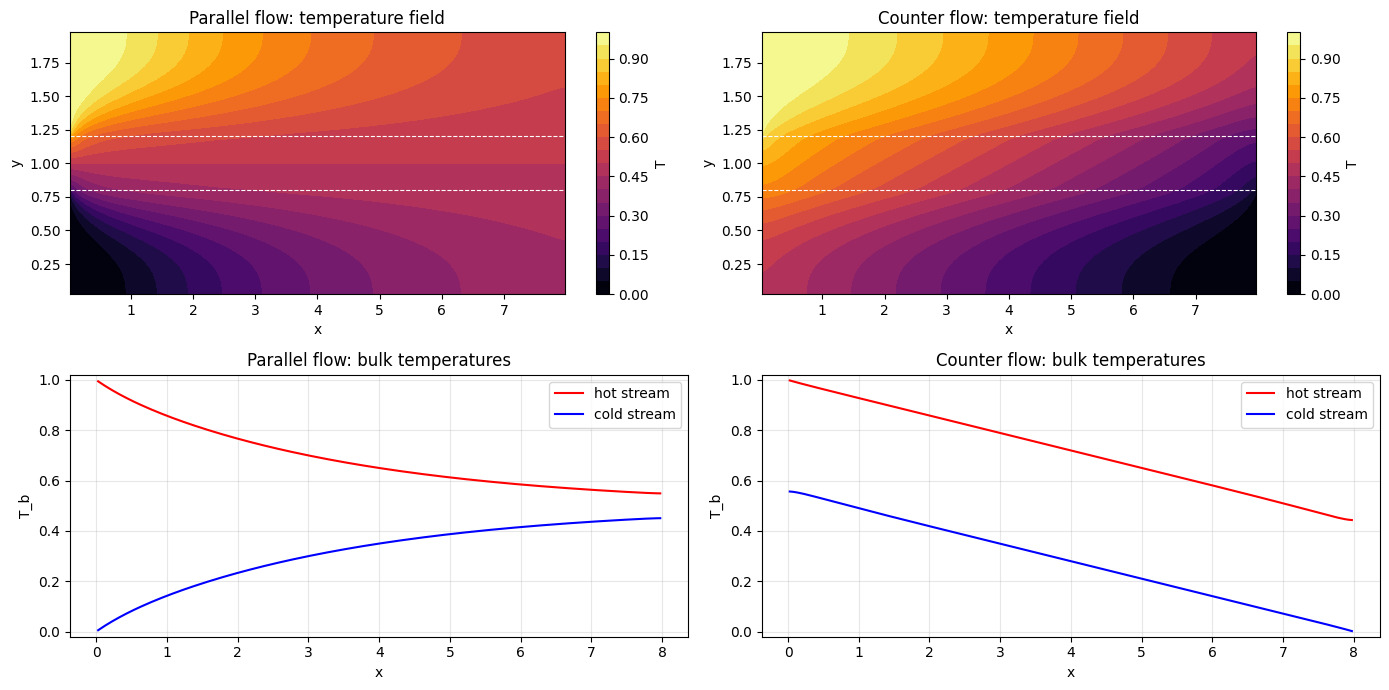

parallel : cold outlet = 0.4507, hot outlet = 0.5493, effectiveness (cold side) = 0.4507, (hot side) = 0.4507
counter  : cold outlet = 0.5567, hot outlet = 0.4433, effectiveness (cold side) = 0.5567, (hot side) = 0.5567


In [2]:
par = exchanger(flow='parallel')
cnt = exchanger(flow='counter')

fig, ax = plt.subplots(2, 2, figsize=(14, 7))
for a, R, ttl in zip(ax[0], (par, cnt), ('Parallel flow', 'Counter flow')):
    X, Y = np.meshgrid(R['xc'], R['yc'], indexing='ij')
    cs = a.contourf(X, Y, R['T'], np.linspace(0, 1, 21), cmap='inferno')
    for yline in (H_C, H_C+H_W): a.axhline(yline, color='w', lw=0.8, ls='--')
    a.set(title=f'{ttl}: temperature field', xlabel='x', ylabel='y')
    fig.colorbar(cs, ax=a, label='T')
for a, R, ttl in zip(ax[1], (par, cnt), ('Parallel flow', 'Counter flow')):
    a.plot(R['xc'], R['Tb_h'], 'r-', label='hot stream')
    a.plot(R['xc'], R['Tb_c'], 'b-', label='cold stream')
    a.set(title=f'{ttl}: bulk temperatures', xlabel='x', ylabel='T_b', ylim=(-0.02, 1.02)); a.legend(); a.grid(alpha=0.3)
plt.tight_layout(); plt.show()

for R in (par, cnt):
    print(f"{R['flow']:9s}: cold outlet = {R['Tc_out']:.4f}, hot outlet = {R['Th_out']:.4f}, "
          f"effectiveness (cold side) = {R['eff_cold']:.4f}, (hot side) = {R['eff_hot']:.4f}")

## 5. Parametric study: Re, Pr and k_s/k_f

In [3]:
rows = []
for Re in (5, 10, 20, 50, 100):
    for fl in ('parallel', 'counter'):
        R = exchanger(Re=Re, flow=fl)
        rows.append(['Re', Re, fl, R['eff_cold'], R['eff_hot'], R['Tc_out'], R['Th_out']])
for Pr in (0.7, 1.0, 7.0):
    for fl in ('parallel', 'counter'):
        R = exchanger(Pr=Pr, flow=fl)
        rows.append(['Pr', Pr, fl, R['eff_cold'], R['eff_hot'], R['Tc_out'], R['Th_out']])
for ksf in (0.2, 1.0, 5.0, 50.0):
    for fl in ('parallel', 'counter'):
        R = exchanger(ksf=ksf, flow=fl)
        rows.append(['k_s/k_f', ksf, fl, R['eff_cold'], R['eff_hot'], R['Tc_out'], R['Th_out']])
study = pd.DataFrame(rows, columns=['varied', 'value', 'flow', 'effectiveness (cold)', 'effectiveness (hot)', 'T cold out', 'T hot out'])
study

,varied,value,flow,effectiveness (cold),effectiveness (hot),T cold out,T hot out
0,Re,5.0,parallel,0.492569,0.492569,0.492569,0.507431
1,Re,5.0,counter,0.699731,0.699731,0.699731,0.300269
2,Re,10.0,parallel,0.450728,0.450728,0.450728,0.549272
3,Re,10.0,counter,0.556653,0.556653,0.556653,0.443347
4,Re,20.0,parallel,0.352862,0.352862,0.352862,0.647138
5,Re,20.0,counter,0.395389,0.395389,0.395389,0.604611
6,Re,50.0,parallel,0.206551,0.206551,0.206551,0.793449
7,Re,50.0,counter,0.220039,0.220039,0.220039,0.779961
8,Re,100.0,parallel,0.127672,0.127672,0.127672,0.872328
9,Re,100.0,counter,0.134129,0.134129,0.134129,0.865871


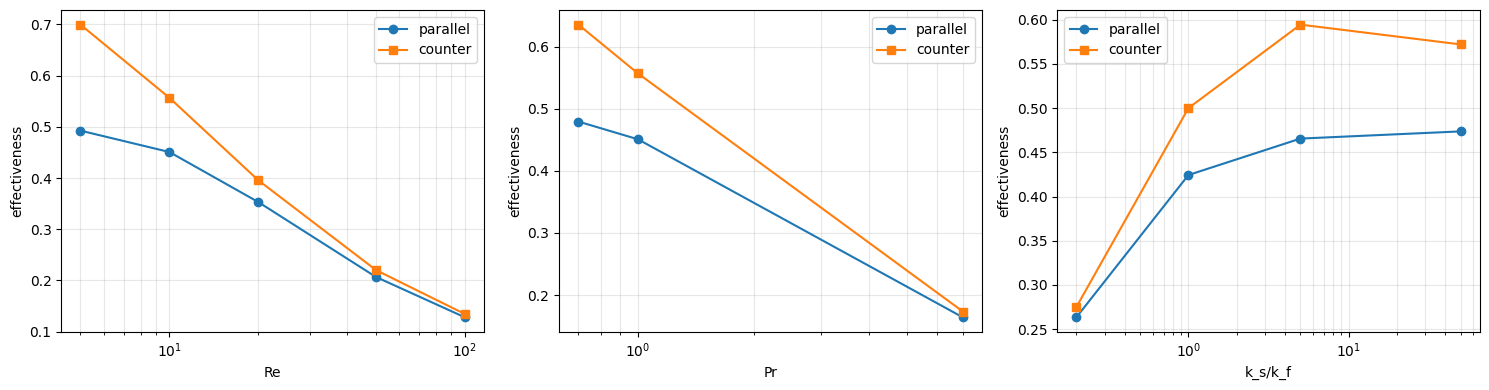

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, name in zip(ax, ('Re', 'Pr', 'k_s/k_f')):
    sub = study[study['varied'] == name]
    for fl, mk in (('parallel', 'o-'), ('counter', 's-')):
        s = sub[sub['flow'] == fl]
        a.plot(s['value'], s['effectiveness (cold)'], mk, label=fl)
    a.set(xlabel=name, ylabel='effectiveness', xscale='log'); a.legend(); a.grid(alpha=0.3, which='both')
plt.tight_layout(); plt.show()